In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.layers import Input, BatchNormalization, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Load CIFAR-10 dataset
(xtrain, ytrain), (xtest, ytest) = datasets.cifar10.load_data()

ytrain = ytrain.reshape(-1,)
ytest = ytest.reshape(-1,)

# Class names
classname = ["airplane","automobile","bird","cat","deer",
             "dog","frog","horse","ship","truck"]


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2474s 15us/step


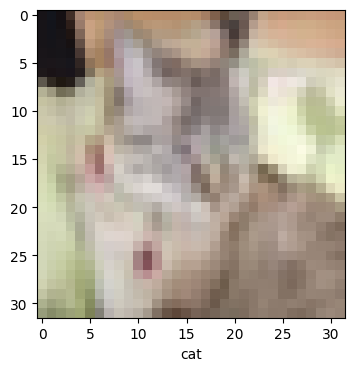

In [ ]:
# Display sample image
def example(x, y, index):
    plt.figure(figsize=(4,4))
    plt.imshow(x[index])
    plt.xlabel(classname[y[index]])
    plt.show()

example(xtest, ytest, 8)

# Normalize images
xtrain = xtrain / 255.0
xtest = xtest / 255.0

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

print("Callbacks 'early_stop' and 'reduce_lr' defined.")

Callbacks 'early_stop' and 'reduce_lr' defined.


## Modified CNN Model Architecture


In [ ]:
def create_cnn_model():
    model = models.Sequential([

        Input(shape=(32,32,3)),

        # Block 1
        layers.Conv2D(32, (3,3), padding='same', activation='relu'),
        BatchNormalization(),

        layers.Conv2D(32, (3,3), padding='same', activation='relu'),
        BatchNormalization(),

        layers.MaxPooling2D((2,2)),
        Dropout(0.25), # Changed dropout

        # Block 2
        layers.Conv2D(64, (3,3), padding='same', activation='relu'),
        BatchNormalization(),

        layers.Conv2D(64, (3,3), padding='same', activation='relu'),
        BatchNormalization(),

        layers.MaxPooling2D((2,2)),
        Dropout(0.30), # Changed dropout

        # Block 3 (Added one more Conv2D layer)
        layers.Conv2D(128, (3,3), padding='same', activation='relu'),
        BatchNormalization(),

        layers.Conv2D(128, (3,3), padding='same', activation='relu'), # Added layer
        BatchNormalization(),

        layers.MaxPooling2D((2,2)),
        Dropout(0.35), # Changed dropout

        # Fully Connected Layers
        layers.Flatten(),

        layers.Dense(256, activation='relu'),
        BatchNormalization(),
        Dropout(0.45), # Changed dropout

        layers.Dense(128, activation='relu'),
        Dropout(0.25), # Changed dropout

        layers.Dense(10, activation='softmax')
    ])
    return model

print("CNN model creation function defined.")

CNN model creation function defined.


### Optimizer Comparison: Adam

Training with Adam optimizer...
Epoch 1/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 29s 20ms/step - accuracy: 0.4455 - loss: 1.5581 - val_accuracy: 0.5431 - val_loss: 1.2604 - learning_rate: 0.0010
Epoch 2/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.6151 - loss: 1.0669 - val_accuracy: 0.5631 - val_loss: 1.2646 - learning_rate: 0.0010
Epoch 3/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.6837 - loss: 0.8948 - val_accuracy: 0.6290 - val_loss: 1.0708 - learning_rate: 0.0010
Epoch 4/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7158 - loss: 0.8066 - val_accuracy: 0.6961 - val_loss: 0.8712 - learning_rate: 0.0010
Epoch 5/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7380 - loss: 0.7461 - val_accuracy: 0.7651 - val_loss: 0.6714 - learning_rate: 0.0010
Epoch 6/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7629 - loss: 0.6874 - val_accuracy: 0.7339 - val_loss: 0.7603 - learning_rate: 0.0010
Epoch 7/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - 

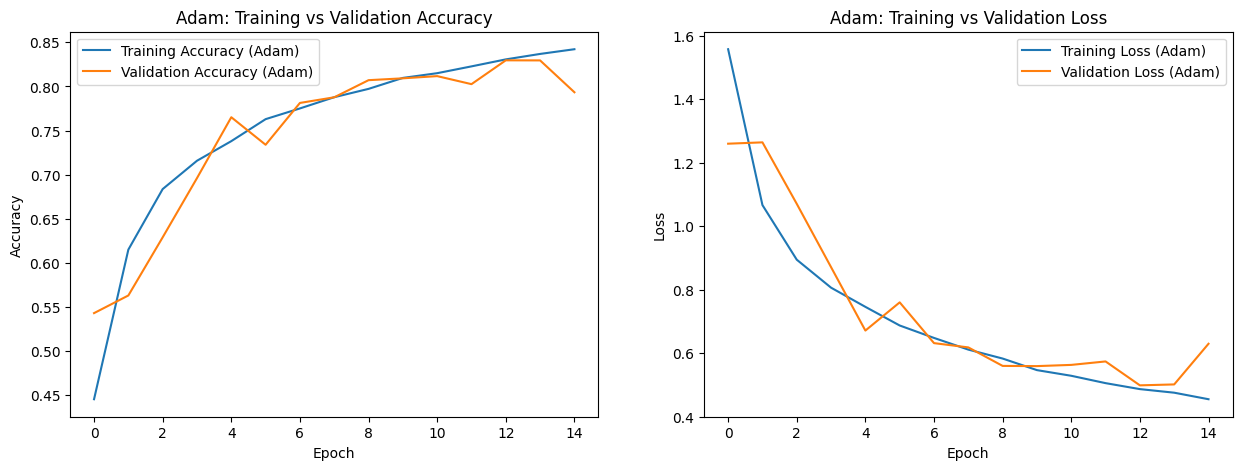

In [ ]:
model_adam = create_cnn_model()
optimizer_adam = tf.keras.optimizers.Adam(learning_rate=0.001)

model_adam.compile(
    optimizer=optimizer_adam,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Training with Adam optimizer...")
history_adam = model_adam.fit(
    xtrain,
    ytrain,
    epochs=15, # Set to 15 epochs as requested
    batch_size=64,
    validation_data=(xtest, ytest),
    callbacks=[early_stop, reduce_lr]
)

loss_adam, acc_adam = model_adam.evaluate(xtest, ytest, verbose=0)
print(f"Adam - Test Accuracy: {acc_adam:.4f}")
print(f"Adam - Test Loss: {loss_adam:.4f}")

plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
plt.plot(history_adam.history['accuracy'], label='Training Accuracy (Adam)')
plt.plot(history_adam.history['val_accuracy'], label='Validation Accuracy (Adam)')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Adam: Training vs Validation Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history_adam.history['loss'], label='Training Loss (Adam)')
plt.plot(history_adam.history['val_loss'], label='Validation Loss (Adam)')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Adam: Training vs Validation Loss")
plt.legend()
plt.show()

### Optimizer Comparison: RMSprop

Training with RMSprop optimizer...
Epoch 1/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 23s 18ms/step - accuracy: 0.4192 - loss: 1.6534 - val_accuracy: 0.5322 - val_loss: 1.3579 - learning_rate: 5.0000e-04
Epoch 2/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.5919 - loss: 1.1550 - val_accuracy: 0.6379 - val_loss: 1.0505 - learning_rate: 5.0000e-04
Epoch 3/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6513 - loss: 0.9823
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.6640 - loss: 0.9510 - val_accuracy: 0.7127 - val_loss: 0.8236 - learning_rate: 5.0000e-04
Epoch 4/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7153 - loss: 0.8136 - val_accuracy: 0.7589 - val_loss: 0.6984 - learning_rate: 2.5000e-04
Epoch 5/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.7354 - loss: 0.7618 - val_accuracy: 0.7499 - val_loss: 0.7124 - learning_rate: 2.5000e-04
Epoch 6/15
776/782 ━━━━━━━━━━━━

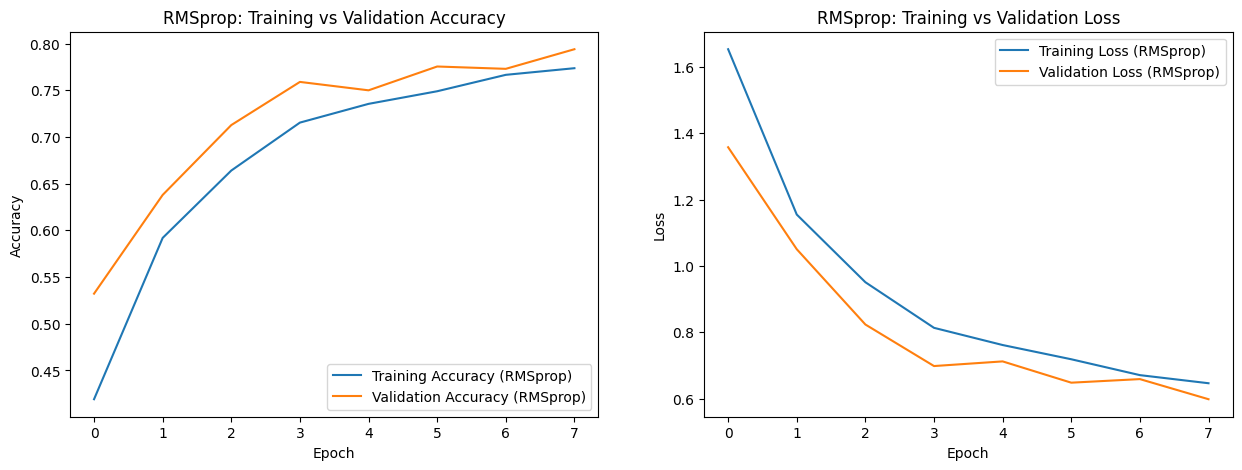

In [ ]:
model_rmsprop = create_cnn_model()
optimizer_rmsprop = tf.keras.optimizers.RMSprop(learning_rate=0.0005)

model_rmsprop.compile(
    optimizer=optimizer_rmsprop,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Training with RMSprop optimizer...")
history_rmsprop = model_rmsprop.fit(
    xtrain,
    ytrain,
    epochs=15, # Set to 15 epochs as requested
    batch_size=64,
    validation_data=(xtest, ytest),
    callbacks=[early_stop, reduce_lr]
)

loss_rmsprop, acc_rmsprop = model_rmsprop.evaluate(xtest, ytest, verbose=0)
print(f"RMSprop - Test Accuracy: {acc_rmsprop:.4f}")
print(f"RMSprop - Test Loss: {loss_rmsprop:.4f}")

plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
plt.plot(history_rmsprop.history['accuracy'], label='Training Accuracy (RMSprop)')
plt.plot(history_rmsprop.history['val_accuracy'], label='Validation Accuracy (RMSprop)')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("RMSprop: Training vs Validation Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history_rmsprop.history['loss'], label='Training Loss (RMSprop)')
plt.plot(history_rmsprop.history['val_loss'], label='Validation Loss (RMSprop)')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("RMSprop: Training vs Validation Loss")
plt.legend()
plt.show()

### Optimizer Comparison: SGD with Momentum

Training with SGD (with Momentum) optimizer...
Epoch 1/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 23s 18ms/step - accuracy: 0.4300 - loss: 1.5857 - val_accuracy: 0.5741 - val_loss: 1.1694 - learning_rate: 0.0100
Epoch 2/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.5828 - loss: 1.1692 - val_accuracy: 0.6546 - val_loss: 0.9768 - learning_rate: 0.0100
Epoch 3/15
776/782 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6375 - loss: 1.0236
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.004999999888241291.
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.6463 - loss: 0.9988 - val_accuracy: 0.7031 - val_loss: 0.8372 - learning_rate: 0.0100
Epoch 4/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.6967 - loss: 0.8622 - val_accuracy: 0.7346 - val_loss: 0.7464 - learning_rate: 0.0050
Epoch 5/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.7165 - loss: 0.8104 - val_accuracy: 0.7365 - val_loss: 0.7480 - learning_rate: 0.0050
Epoch 6/15
778/782 ━━━━━━━━━━━━━━━━━━━━ 0

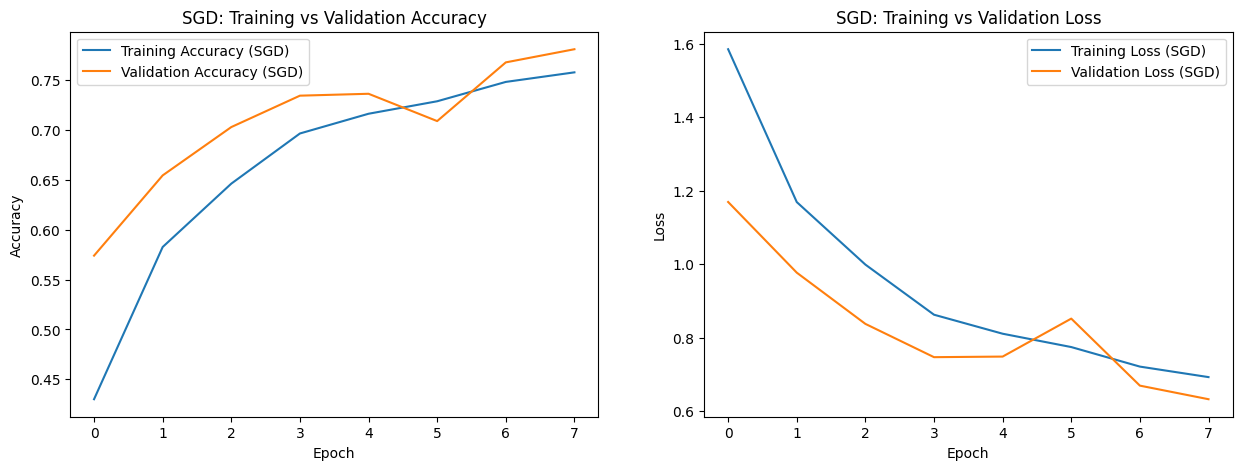

In [ ]:
model_sgd = create_cnn_model()
optimizer_sgd = tf.keras.optimizers.SGD(
    learning_rate=0.01,
    momentum=0.9,
    nesterov=True
)

model_sgd.compile(
    optimizer=optimizer_sgd,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Training with SGD (with Momentum) optimizer...")
history_sgd = model_sgd.fit(
    xtrain,
    ytrain,
    epochs=15, # Set to 15 epochs as requested
    batch_size=64,
    validation_data=(xtest, ytest),
    callbacks=[early_stop, reduce_lr]
)

loss_sgd, acc_sgd = model_sgd.evaluate(xtest, ytest, verbose=0)
print(f"SGD - Test Accuracy: {acc_sgd:.4f}")
print(f"SGD - Test Loss: {loss_sgd:.4f}")

plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
plt.plot(history_sgd.history['accuracy'], label='Training Accuracy (SGD)')
plt.plot(history_sgd.history['val_accuracy'], label='Validation Accuracy (SGD)')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("SGD: Training vs Validation Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history_sgd.history['loss'], label='Training Loss (SGD)')
plt.plot(history_sgd.history['val_loss'], label='Validation Loss (SGD)')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("SGD: Training vs Validation Loss")
plt.legend()
plt.show()

In [ ]:
print(f"### Summary of Optimizer Performance\n")
print(f"Here's a quick comparison of the test accuracies and losses for each optimizer:\n")
print(f"- **Adam:** Test Accuracy: {acc_adam:.4f}, Test Loss: {loss_adam:.4f}")
print(f"- **RMSprop:** Test Accuracy: {acc_rmsprop:.4f}, Test Loss: {loss_rmsprop:.4f}")
print(f"- **SGD with Momentum:** Test Accuracy: {acc_sgd:.4f}, Test Loss: {loss_sgd:.4f}")
print(f"\nReview the plots above to see the training progress for each optimizer.")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 848,554 (3.24 MB)

 Trainable params: 847,146 (3.23 MB)

 Non-trainable params: 1,408 (5.50 KB)

Training the initial model with Adam optimizer...
Epoch 1/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 27s 20ms/step - accuracy: 0.4120 - loss: 1.6846 - val_accuracy: 0.5281 - val_loss: 1.3189 - learning_rate: 0.0010
Epoch 2/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.5869 - loss: 1.1586 - val_accuracy: 0.6553 - val_loss: 0.9972 - learning_rate: 0.0010
Epoch 3/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.6618 - loss: 0.9659 - val_accuracy: 0.6970 - val_loss: 0.8500 - learning_rate: 0.0010
Epoch 4/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.7023 - loss: 0.8538 - val_accuracy: 0.7222 - val_loss: 0.8039 - learning_rate: 0.0010
Epoch 5/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.7310 - loss: 0.7765 - val_accuracy: 0.7592 - val_loss: 0.7024 - learning_rate: 0.0010
Epoch 6/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.7553 - loss: 0.7146 - val_accuracy: 0.7332 - val_loss: 0.7811 - learning_rate: 0.0010
Epoch 7/15
782/782 ━━━━━━━━━━━━

Callbacks 'early_stop' and 'reduce_lr' defined.


Test Accuracy: 0.8517000079154968
Test Loss: 0.44304516911506653


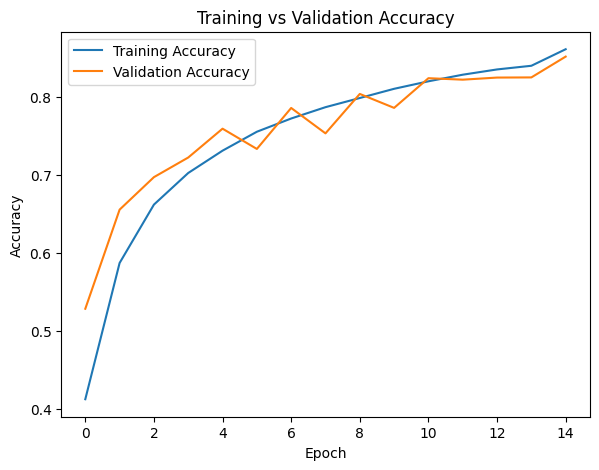

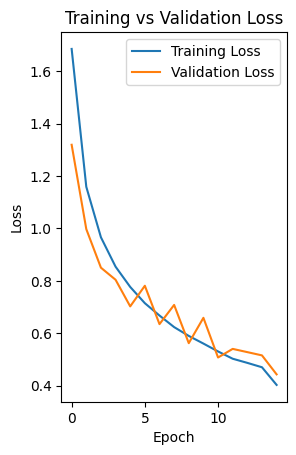

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step
True: cat 	Predicted: cat
True: ship 	Predicted: ship
True: ship 	Predicted: ship
True: airplane 	Predicted: airplane
True: frog 	Predicted: frog
